# 04 — Tests du cœur statistique sur la calibration des modèles de PD
Entrée : `data/processed/tableau_coeur_{AN}_{cible}.csv` (notebook 03). Résidu = observé − prédit ; **négatif = le modèle surestime le risque (prudent)**, positif = il le sous-estime.
Cible principale : `defaut_hors_forbearance`. Sensibilité : `defaut` (forbearance 2020 comptée comme défaut).

In [9]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RACINE = Path.cwd().parent
sys.path.insert(0, str(RACINE / "src"))
from validation_toolkit.core.stat_tests import (
    moyenne_newey_west, diebold_mariano, ajouter_regime, perte_annuelle)

PROC = RACINE / "data" / "processed"

In [10]:
AN = 2015            # 2007 ou 2015
SEUIL = 30           # défauts minimum par classe (config/freddie_mac.yaml)

# colonne « observé » à utiliser selon la cible d'entraînement
OBSERVE = {"principal": "observe_hors_forbearance", "sensibilite": "observe"}
EVENTS  = {"principal": "n_evenements_hors_forbearance", "sensibilite": "n_evenements"}

# frontières de régime, définies par le calendrier et non par le millésime
# (à confirmer avec des séries agrégées FRED, pas avec les résultats du modèle)
REGIMES = [("crise_2008", 2008, 2010), ("stress_2020", 2020, 2020)]

In [11]:
def charger(an, nom):
    c = pd.read_csv(PROC / f"tableau_coeur_{an}_{nom}.csv")
    c["obs"] = c[OBSERVE[nom]]
    c["ev"] = c[EVENTS[nom]]
    return c

coeur = {nom: charger(AN, nom) for nom in OBSERVE}
print({nom: (c["date"].min(), c["date"].max()) for nom, c in coeur.items()})

{'principal': (np.int64(2019), np.int64(2026)), 'sensibilite': (np.int64(2019), np.int64(2026))}


## 1. Biais annuel agrégé et test Newey-West
Pour chaque modèle : écart (observé − prédit) de l'année, moyenné sur les classes pondérées par n. Test de H0 « biais moyen = 0 » avec erreur standard robuste à l'autocorrélation.

In [12]:
def serie_annuelle(c, modele):
    g = c[c["modele"] == modele].groupby("date")
    s = pd.DataFrame({"obs": g.apply(lambda h: np.average(h["obs"], weights=h["n"]), include_groups=False),
                      "pred": g.apply(lambda h: np.average(h["predit"], weights=h["n"]), include_groups=False)})
    s["residu"] = s["obs"] - s["pred"]
    return s

lignes, series = [], {}
for nom, c in coeur.items():
    for m in ("ref", "chall"):
        s = serie_annuelle(c, m)
        series[(nom, m)] = s
        r = moyenne_newey_west(s["residu"].values)
        lignes.append({"cible": nom, "modele": m, "n_annees": r["n"], "biais_moyen": r["moyenne"],
                       "se_NW": r["se"], "t": r["t"], "p": r["p"], "retards": r["retards"]})
tab_biais = pd.DataFrame(lignes)
tab_biais.round(4)

,cible,modele,n_annees,biais_moyen,se_NW,t,p,retards
0,principal,ref,8,-0.0005,0.0004,-1.1494,0.2882,2
1,principal,chall,8,-0.0003,0.0002,-1.5846,0.1571,2
2,sensibilite,ref,8,-0.0123,0.0060,-2.0488,0.0797,2
3,sensibilite,chall,8,-0.0000,0.0031,-0.0081,0.9938,2


## 2. Calibration par classe de risque (toutes années test cumulées)
Une classe n'est jugée que si elle compte au moins `SEUIL` défauts cumulés.

In [13]:
def par_classe(c):
    g = c.groupby(["modele", "groupe"])
    out = pd.DataFrame({
        "n": g["n"].sum(),
        "defauts": g["ev"].sum(),
        "predit": g.apply(lambda h: np.average(h["predit"], weights=h["n"]), include_groups=False)})
    out["observe"] = out["defauts"] / out["n"]
    out["residu"] = out["observe"] - out["predit"]
    out["concluante"] = out["defauts"] >= SEUIL
    return out.reset_index()

for nom, c in coeur.items():
    print(f"\n--- cible : {nom}")
    display(par_classe(c).query("modele == 'ref'").round(4).assign(modele="ref"))
    display(par_classe(c).query("modele == 'chall'").round(4))


--- cible : principal


,modele,groupe,n,defauts,predit,observe,residu,concluante
10,ref,1,15619,1,0.0002,0.0001,-0.0002,False
11,ref,2,15622,5,0.0004,0.0003,-0.0001,False
12,ref,3,15621,11,0.0006,0.0007,0.0001,False
13,ref,4,15623,12,0.0009,0.0008,-0.0001,False
14,ref,5,15622,25,0.0012,0.0016,0.0004,False
15,ref,6,15621,28,0.0016,0.0018,0.0002,False
16,ref,7,15622,49,0.0022,0.0031,0.0010,True
17,ref,8,15622,36,0.0030,0.0023,-0.0007,True
18,ref,9,15621,50,0.0047,0.0032,-0.0015,True
19,ref,10,15626,101,0.0129,0.0065,-0.0064,True


,modele,groupe,n,defauts,predit,observe,residu,concluante
0,chall,1,15619,4,0.0001,0.0003,0.0002,False
1,chall,2,15622,6,0.0002,0.0004,0.0002,False
2,chall,3,15621,15,0.0004,0.0010,0.0006,False
3,chall,4,15623,7,0.0006,0.0004,-0.0002,False
4,chall,5,15622,22,0.0009,0.0014,0.0005,False
5,chall,6,15621,36,0.0013,0.0023,0.0010,True
6,chall,7,15622,32,0.0019,0.0020,0.0002,True
7,chall,8,15622,64,0.0028,0.0041,0.0013,True
8,chall,9,15621,56,0.0046,0.0036,-0.0010,True
9,chall,10,15626,76,0.0124,0.0049,-0.0075,True



--- cible : sensibilite


,modele,groupe,n,defauts,predit,observe,residu,concluante
10,ref,1,15619,23,0.0026,0.0015,-0.0011,False
11,ref,2,15622,43,0.0045,0.0028,-0.0018,True
12,ref,3,15621,70,0.0062,0.0045,-0.0017,True
13,ref,4,15623,75,0.0081,0.0048,-0.0033,True
14,ref,5,15622,112,0.0104,0.0072,-0.0032,True
15,ref,6,15621,150,0.0132,0.0096,-0.0036,True
16,ref,7,15622,176,0.0170,0.0113,-0.0057,True
17,ref,8,15622,221,0.0224,0.0141,-0.0082,True
18,ref,9,15621,285,0.0315,0.0182,-0.0133,True
19,ref,10,15626,401,0.0631,0.0257,-0.0374,True


,modele,groupe,n,defauts,predit,observe,residu,concluante
0,chall,1,15619,25,0.0008,0.0016,0.0008,False
1,chall,2,15622,46,0.0015,0.0029,0.0014,True
2,chall,3,15621,75,0.0023,0.0048,0.0025,True
3,chall,4,15623,93,0.0033,0.0060,0.0027,True
4,chall,5,15622,116,0.0045,0.0074,0.0029,True
5,chall,6,15621,156,0.0062,0.0100,0.0038,True
6,chall,7,15622,201,0.0082,0.0129,0.0047,True
7,chall,8,15622,215,0.0108,0.0138,0.0029,True
8,chall,9,15621,279,0.0149,0.0179,0.0030,True
9,chall,10,15626,350,0.0277,0.0224,-0.0053,True


## 3. Résultats par régime

In [14]:
def par_regime(c):
    c = ajouter_regime(c, "date", REGIMES)
    lignes = []
    for (m, reg), h in c.groupby(["modele", "regime"]):
        lignes.append({"modele": m, "regime": reg, "annees": h["date"].nunique(), "n": h["n"].sum(),
                       "defauts": h["ev"].sum(),
                       "observe": h["ev"].sum() / h["n"].sum(),
                       "predit": np.average(h["predit"], weights=h["n"])})
    t = pd.DataFrame(lignes)
    t["residu"] = t["observe"] - t["predit"]
    return t

for nom, c in coeur.items():
    print(f"\n--- cible : {nom}")
    display(par_regime(c).round(4))
print("Si une période de régime ne contient aucune année de test, elle n'apparaît pas : aucune conclusion possible sur elle.")


--- cible : principal


,modele,regime,annees,n,defauts,observe,predit,residu
0,chall,normal,7,124276,256,0.0021,0.0023,-0.0002
1,chall,stress_2020,1,31943,62,0.0019,0.0035,-0.0015
2,ref,normal,7,124276,256,0.0021,0.0026,-0.0005
3,ref,stress_2020,1,31943,62,0.0019,0.0036,-0.0016



--- cible : sensibilite


,modele,regime,annees,n,defauts,observe,predit,residu
0,chall,normal,7,124276,441,0.0035,0.0090,-0.0055
1,chall,stress_2020,1,31943,1115,0.0349,0.0041,0.0309
2,ref,normal,7,124276,441,0.0035,0.0214,-0.0178
3,ref,stress_2020,1,31943,1115,0.0349,0.0044,0.0305


Si une période de régime ne contient aucune année de test, elle n'apparaît pas : aucune conclusion possible sur elle.


## 4. Référence contre challenger (Diebold-Mariano)
Perte annuelle = erreur quadratique de calibration par année. Moyenne > 0 : le challenger perd moins que la référence.

In [15]:
lignes = []
for nom, c in coeur.items():
    cc = c.assign(observe=c["obs"])
    pr, pc = perte_annuelle(cc, "ref"), perte_annuelle(cc, "chall")
    d = diebold_mariano(pr.values, pc.values)
    lignes.append({"cible": nom, "n_annees": d["n"], "ecart_moyen_perte": d["moyenne"], "t": d["t"], "p": d["p"]})
pd.DataFrame(lignes)

,cible,n_annees,ecart_moyen_perte,t,p
0,principal,8,-0.000001,-1.056183,0.325967
1,sensibilite,8,0.000678,2.337066,0.052069


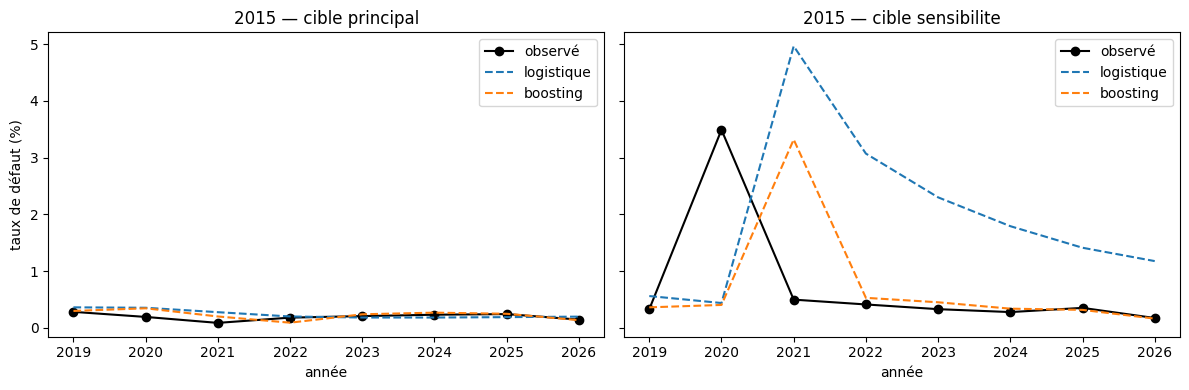

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, nom in zip(axes, OBSERVE):
    ax.plot(series[(nom, "ref")].index, 100 * series[(nom, "ref")]["obs"], "k-o", label="observé")
    ax.plot(series[(nom, "ref")].index, 100 * series[(nom, "ref")]["pred"], "--", label="logistique")
    ax.plot(series[(nom, "chall")].index, 100 * series[(nom, "chall")]["pred"], "--", label="boosting")
    ax.set_title(f"{AN} — cible {nom}"); ax.set_xlabel("année"); ax.legend()
axes[0].set_ylabel("taux de défaut (%)")
plt.tight_layout(); plt.show()

## Limites à retenir
- 8 années de test pour 2015, 16 pour 2007 : les tests sur série annuelle ont peu de puissance. Un résultat non significatif n'est pas une preuve d'absence de biais.
- Les régimes sont définis par le calendrier, identiques pour les deux millésimes. La crise 2008–2010 précède la première année de test des deux millésimes (2011 et 2019) : elle n'est jamais observée hors échantillon, donc aucune conclusion sur le comportement en crise financière.
- 2020 est le seul régime de stress présent dans les années de test, et hors forbearance ce n'est plus une crise de crédit.
- Le modèle validé est celui que nous avons construit : ce n'est pas une validation indépendante au sens réglementaire.